## Figures for the README

Run this notebook from the repository root. It writes two figures to `gallery/`:

1. Density of the public Rubin observations of solar-system objects, with the catalogue asteroids overlaid.
2. Rotation periods in the catalogue compared with the JPL Small-Body Database and with Greenstreet et al. (2026).


In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
sys.path.insert(0, str(root / "code"))
from util import DEG, f2m, split_mollweide

gallery = root / "gallery"
gallery.mkdir(exist_ok=True)
data_file = root / "code" / "data" / "obs_sbn_X05_full.parquet"
catalogue_file = root / "medellin-vroc-latest.csv"


### Catalogue properties

Write a short description of the sample to `gallery/catalogue_props.md`, then read that file into the top of `CATALOGUE.md`.


In [19]:
catalogue = pd.read_csv(catalogue_file)

def count(column):
    return int(catalogue[column].notna().sum())

def span(column, digits):
    values = pd.to_numeric(catalogue[column], errors="coerce").dropna()
    return values.min(), values.median(), values.max(), digits

n = len(catalogue)
n_obs = catalogue["n_obs"]
epoch_ini = str(catalogue["epoch_utc_ini"].min())[:10]
epoch_end = str(catalogue["epoch_utc_end"].max())[:10]
band_rows = []
for band in "ugrizy":
    column = f"n_obs_{band}"
    observed = catalogue.loc[catalogue[column] > 0, column]
    band_rows.append(f"| {band} | {len(observed)} | {observed.mean():.1f} |")
band_rows.append(f"| all | {n} | {n_obs.mean():.1f} |")
band_table = "\n".join(band_rows)
unanimous = int((catalogue["votes_dem"] == catalogue["n_series_dem"]).sum())

def row(name, column, digits):
    lo, mid, hi, digits = span(column, digits)
    return f"| {name} | {lo:.{digits}f} | {mid:.{digits}f} | {hi:.{digits}f} |"

props = f"""## Sample

The catalogue contains {n} asteroids and {catalogue.shape[1]} columns. The measurements run from {epoch_ini} to {epoch_end}. Each asteroid has between {int(n_obs.min())} and {int(n_obs.max())} measurements (median {n_obs.median():.0f}). The sample contains {int(n_obs.sum())} measurements in all.

{count("permid")} asteroids are numbered. An orbit is filled for {count("a")} asteroids and a multiband rotation period for {count("p_rot_multi_h")}. `H_r` is filled for {count("H_r")} asteroids, `g-r` for {count("g-r")}, a JPL rotation period for {count("rot_per_sbdb")}, and a Greenstreet et al. (2026) period for {count("rot_per_lsm_gst")}. The vote is unanimous for {unanimous} asteroids.

The mean in each band is the average number of measurements among asteroids with at least one measurement in that band. The last row is the mean of `n_obs`.

| Band | Asteroids with observations | Mean observations per asteroid |
|---|---:|---:|
{band_table}

| Quantity | Minimum | Median | Maximum |
|---|---:|---:|---:|
{row("Measurements", "n_obs", 0)}
{row("Semimajor axis [au]", "a", 2)}
{row("Eccentricity", "e", 3)}
{row("Inclination [deg]", "incl", 2)}
{row("$H_r$ [mag]", "H_r", 2)}
{row("Rotation period [h]", "p_rot_multi_h", 2)}
"""

props_path = gallery / "catalogue_props.md"
props_path.write_text(props)
props_text = props_path.read_text().strip()
catalogue_doc = (root / "CATALOGUE.md").read_text()
begin = "<!-- begin catalogue_props.md -->"
end = "<!-- end catalogue_props.md -->"
block = f"{begin}\n\n{props_text}\n\n{end}"
pre, rest = catalogue_doc.split(begin, 1)
_, post = rest.split(end, 1)
(root / "CATALOGUE.md").write_text(pre + block + post)
print(f"wrote {props_path}")


wrote /Users/jzuluaga/dev/rubin-workshop/medellin_workshop_solarsystem/gallery/catalogue_props.md


### Density of VRO solar-system observations

Same hexbin as `code/dev_data.ipynb`. Right ascension is folded so that 0° sits at the centre of the Mollweide projection. Each white point is one asteroid in `medellin-vroc-latest.csv`, at the mean position of its measurements. The ecliptic and the galactic equator are read from `data/ecliptic.csv` and `data/galaxy.csv`.


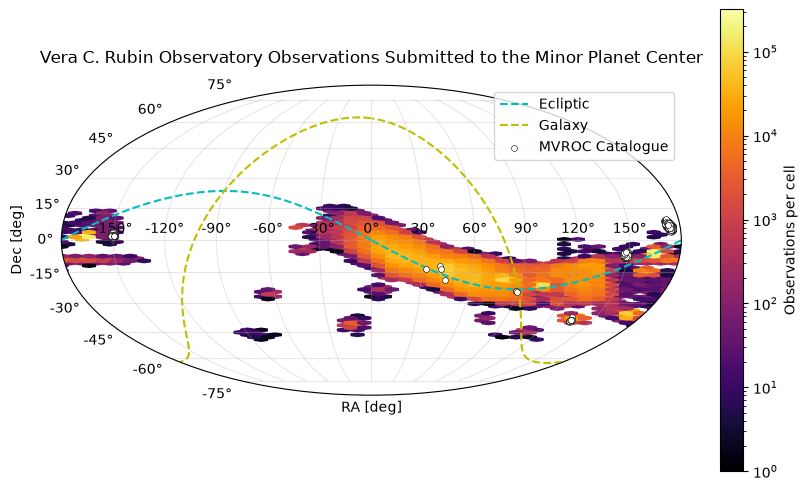

In [9]:
observations = pd.read_parquet(data_file, columns=["provid", "ra", "dec"])
observations[["ra", "dec"]] = observations[["ra", "dec"]].apply(pd.to_numeric, errors="coerce")
observations = observations.dropna(subset=["ra", "dec"])

catalogue = pd.read_csv(catalogue_file)
catalogue_obs = observations[observations["provid"].isin(catalogue["provid"])].copy()
ra_rad = np.deg2rad(catalogue_obs["ra"].to_numpy())
catalogue_obs["sin_ra"] = np.sin(ra_rad)
catalogue_obs["cos_ra"] = np.cos(ra_rad)
sky = catalogue_obs.groupby("provid").agg(
    sin_ra=("sin_ra", "mean"),
    cos_ra=("cos_ra", "mean"),
    dec=("dec", "mean"),
)
sky["ra"] = np.rad2deg(np.arctan2(sky["sin_ra"], sky["cos_ra"])) % 360
ecliptic = pd.read_csv(root / "data" / "ecliptic.csv")
galaxy = pd.read_csv(root / "data" / "galaxy.csv")

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection="mollweide")
hb = ax.hexbin(
    f2m(observations["ra"]) * DEG,
    observations["dec"] * DEG,
    gridsize=50,
    bins="log",
    cmap="inferno",
    zorder=1,
)
fig.colorbar(hb, label="Observations per cell")
ax.plot(*split_mollweide(ecliptic["ra"], ecliptic["dec"]), "c--", label="Ecliptic", zorder=2)
ax.plot(*split_mollweide(galaxy["ra"], galaxy["dec"]), "y--", label="Galaxy", zorder=2)
ax.scatter(
    f2m(sky["ra"]) * DEG,
    sky["dec"] * DEG,
    s=18,
    c="white",
    edgecolors="k",
    linewidths=0.4,
    label="MVROC Catalogue",
    zorder=3,
)
ax.legend()
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title(
    "Vera C. Rubin Observatory Observations Submitted to the Minor Planet Center",
    pad=16,
)
ax.grid(alpha=0.3)
fig.savefig(gallery / "vro-observations-hexbin.png", dpi=150, bbox_inches="tight")
plt.show()


### Rotation periods: MVROC, the SBDB, and Greenstreet et al. (2026)

`p_rot_multi_h` is the period of the multiband fit, in hours. `rot_per_sbdb` is the period from the JPL Small-Body Database. `rot_per_lsm_gst` is the Lomb–Scargle period of Greenstreet et al. (2026), stored in the catalogue. The dashed lines are the double-period aliases.


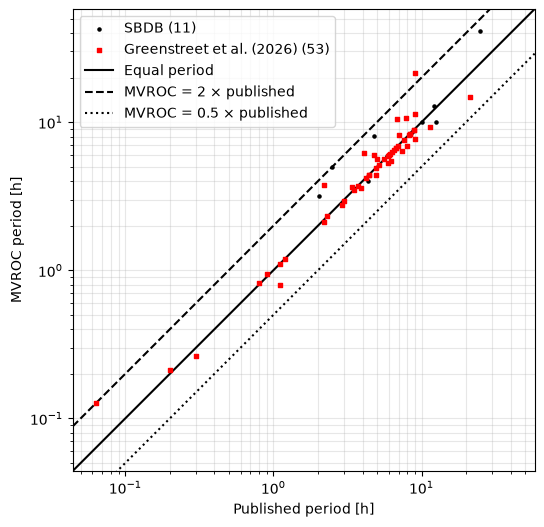

In [18]:
catalogue_file = "medellin-vroc-latest.csv"
catalogue = pd.read_csv(catalogue_file)

# Extract periods already published in the JPL's Small-Body Database
sbdb = catalogue.dropna(subset=["p_rot_multi_h", "rot_per_sbdb"])
# Extract periods published in Greenstreet et al. (2026)
greenstreet = catalogue.dropna(subset=["p_rot_multi_h", "rot_per_lsm_gst"])

# Combine all periods
periods = np.concatenate([
    sbdb["rot_per_sbdb"], sbdb["p_rot_multi_h"],
    greenstreet["rot_per_lsm_gst"], greenstreet["p_rot_multi_h"],
])

# Plot periods 
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sbdb["rot_per_sbdb"], sbdb["p_rot_multi_h"], s=5, c="k", zorder=3,
           label=f"SBDB ({len(sbdb)})")
ax.scatter(greenstreet["rot_per_lsm_gst"], greenstreet["p_rot_multi_h"], s=5, c="r", marker="s", zorder=3,
           label=f"Greenstreet et al. (2026) ({len(greenstreet)})")

# Decoration
limits = np.array([periods.min() * 0.7, periods.max() * 1.4])
ax.plot(limits, limits, "k-", label="Equal period")
ax.plot(limits, 2 * limits, "k--", label="MVROC = 2 × published")
ax.plot(limits, 0.5 * limits, "k:", label="MVROC = 0.5 × published")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal")
ax.set_xlabel("Published period [h]")
ax.set_ylabel("MVROC period [h]")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, which="both")

# Save figure
fig.savefig(gallery / "mvroc-sbdb-periods.png", dpi=150, bbox_inches="tight")
